In [107]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import percentileofscore
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

In [108]:
meu_dataframe = pd.read_csv('lista_jogadores_20-24.csv')

Esta função é desenhada para avaliar o desempenho de um jogador específico em uma determinada métrica, comparando-o com todos os outros jogadores dentro de um período e competição definidos. A ideia é dar contexto ao número do jogador, respondendo se o seu desempenho é mediano, acima da média, ou de elite.

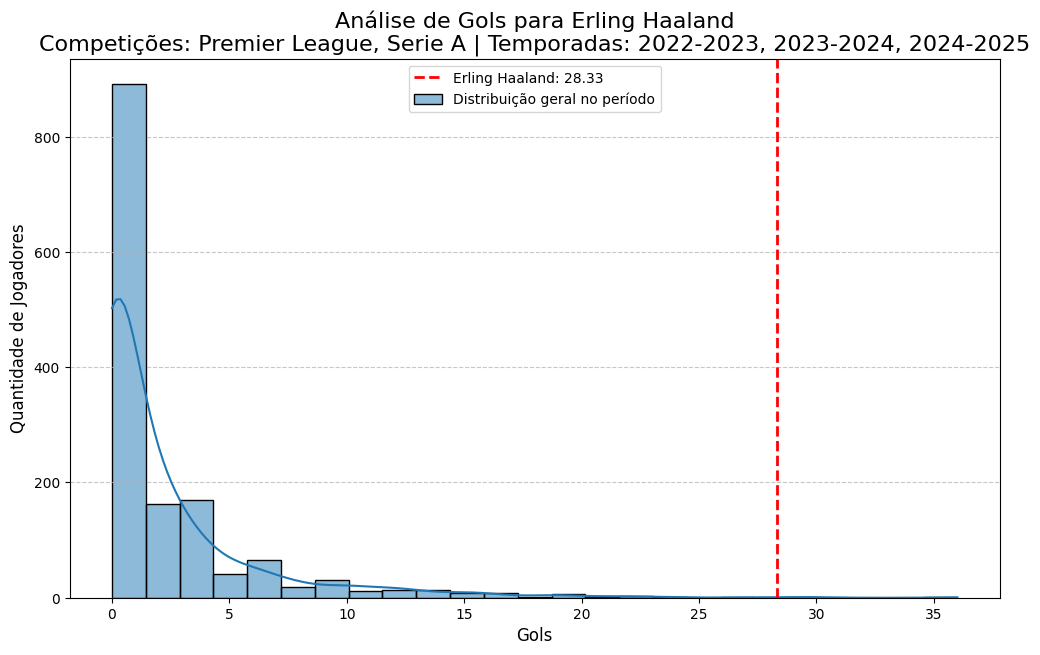


--- Comparativo de 'Gols' em Premier League, Serie A (2022-2023, 2023-2024, 2024-2025) ---
Erling Haaland (média no período): 28.33
Média geral (mesmo período): 2.30
Jogador com maior média em Gols: Harry Kane (30.00)


In [145]:
def analise_desempenho_individual(df, nome_jogador, metrica, temporadas=None, competicoes=None):
    # Prepara os títulos para o gráfico
    titulo_temporada = "Todas as Temporadas"
    titulo_competicao = "Todas as Competições"
    
    # Filtra o DataFrame
    df_filtrado = df.copy()
    if temporadas:
        df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
        titulo_temporada = ", ".join(map(str, temporadas))
    if competicoes:
        df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
        titulo_competicao = ", ".join(competicoes)

    if df_filtrado.empty:
        print("Erro: Nenhum dado encontrado para os filtros de temporada e/ou competição selecionados.")
        return

    # Encontra os dados do jogador no período e contexto selecionados
    dados_jogador = df_filtrado[df_filtrado['Jogador'] == nome_jogador]
    if dados_jogador.empty:
        print(f"Erro: Jogador '{nome_jogador}' não encontrado para os filtros selecionados.")
        return

    valor_jogador = dados_jogador[metrica].mean()
    media_geral = df_filtrado[metrica].mean()
    mediana = df_filtrado[metrica].median()
    medias_jogadores = df_filtrado.groupby('Jogador')[metrica].mean()
    melhor_jogador = medias_jogadores.idxmax()
    melhor_media = medias_jogadores.max()

    # Cria o gráfico
    plt.figure(figsize=(12, 7))
    sns.histplot(df_filtrado[metrica], kde=True, bins=25, label=f'Distribuição geral no período')
    plt.axvline(x=valor_jogador, color='red', linestyle='--', linewidth=2, label=f'{nome_jogador}: {valor_jogador:.2f}')
    # plt.axvline(mediana, color='g', linestyle='-', label='Mediana')
    
    plt.title(f'Análise de {metrica} para {nome_jogador}\nCompetições: {titulo_competicao} | Temporadas: {titulo_temporada}', fontsize=16)
    plt.xlabel(metrica, fontsize=12)
    plt.ylabel('Quantidade de Jogadores', fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    print(f"\n--- Comparativo de '{metrica}' em {titulo_competicao} ({titulo_temporada}) ---")
    print(f"{nome_jogador} (média no período): {valor_jogador:.2f}")
    print(f"Média geral (mesmo período): {media_geral:.2f}")
    # print(f"Mediana (mesmo período): {mediana:.2f}")
    print(f"Jogador com maior média em {metrica}: {melhor_jogador} ({melhor_media:.2f})")

# analise_desempenho_individual(
#     meu_dataframe,
#     'Kevin De Bruyne',
#     'Assistências',
#     temporadas=['2020-2021', '2021-2022', '2022-2023', '2023-2024'],
#     competicoes=['Premier League']
# )
# analise_desempenho_individual(
#     meu_dataframe,
#     'Virgil van Dijk',
#     'Disputas Aéreas Vencidas',
#     temporadas=['2023-2024', '2024-2025'],
#     competicoes=[]
# )
analise_desempenho_individual(
    meu_dataframe,
    'Erling Haaland',
    'Gols',
    temporadas=['2022-2023', '2023-2024', '2024-2025'],
    competicoes=['Premier League', 'Serie A']
)

Esta função cria um perfil tático ou de estilo para um jogador. Ela o compara não com todos os jogadores, mas com seus pares diretos, aqueles que jogam na mesma posição. Isso ajuda a identificar os pontos fortes e fracos de um jogador em relação ao que é esperado para sua função em campo.

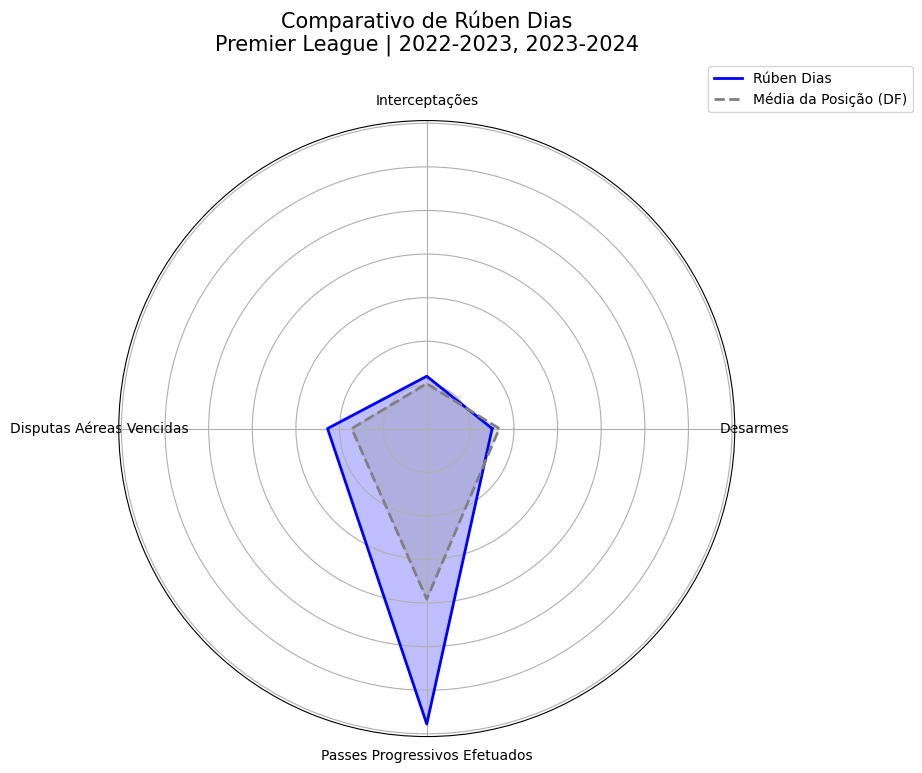

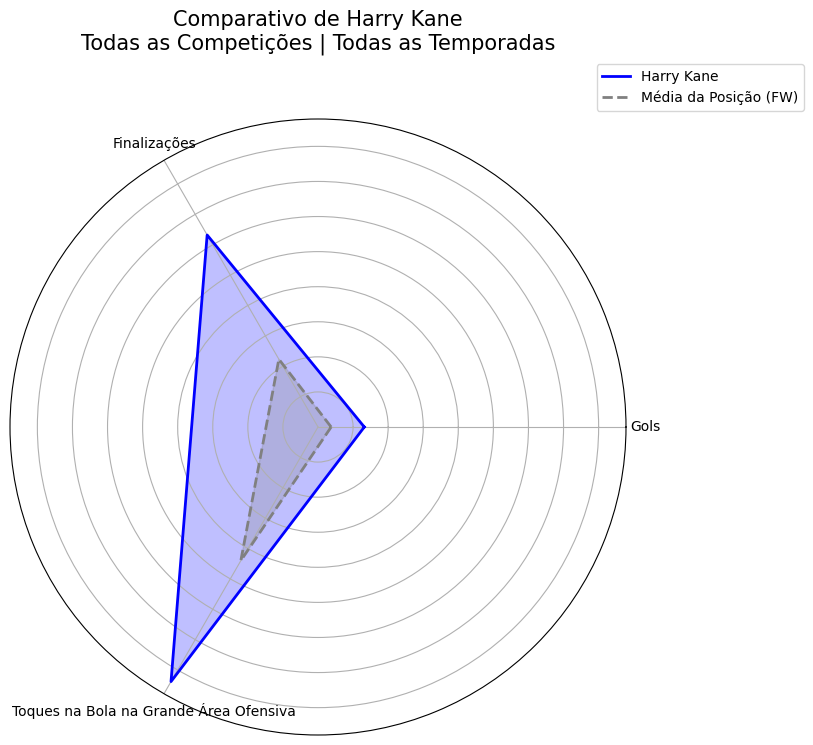

In [146]:
def compara_jogador_metricas(df, nome_jogador, metricas, temporadas=None, competicoes=None):
    titulo_temporada = "Todas as Temporadas"
    titulo_competicao = "Todas as Competições"

    df_filtrado = df.copy()
    if temporadas:
        df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
        titulo_temporada = ", ".join(map(str, temporadas))
    if competicoes:
        df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
        titulo_competicao = ", ".join(competicoes)

    if df_filtrado.empty:
        print("Erro: Nenhum dado encontrado para os filtros de temporada e/ou competição selecionados.")
        return
            
    dados_jogador = df_filtrado[df_filtrado['Jogador'] == nome_jogador]
    if dados_jogador.empty:
        print(f"Erro: Jogador '{nome_jogador}' não encontrado para os filtros selecionados.")
        return
        
    posicao_jogador = dados_jogador['Posição'].iloc[0]
    valores_jogador = dados_jogador[metricas].mean().values

    # Média da posição no mesmo período e contexto
    df_posicao = df_filtrado[df_filtrado['Posição'] == posicao_jogador]
    valores_media_posicao = df_posicao[metricas].mean().values

    # Lógica do gráfico de radar
    labels = np.array(metricas)
    num_vars = len(labels)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1] 

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    valores_jogador = np.concatenate((valores_jogador, [valores_jogador[0]]))
    valores_media_posicao = np.concatenate((valores_media_posicao, [valores_media_posicao[0]]))

    ax.plot(angles, valores_jogador, color='blue', linewidth=2, label=nome_jogador)
    ax.fill(angles, valores_jogador, color='blue', alpha=0.25)
    ax.plot(angles, valores_media_posicao, color='gray', linewidth=2, linestyle='dashed', label=f'Média da Posição ({posicao_jogador})')
    ax.fill(angles, valores_media_posicao, color='gray', alpha=0.25)

    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    plt.title(f'Comparativo de {nome_jogador}\n{titulo_competicao} | {titulo_temporada}', size=15, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()

# Exemplo de uso:
metricas_zagueiro = ['Desarmes', 'Interceptações', 'Disputas Aéreas Vencidas', 'Passes Progressivos Efetuados']
metricas_ataque = ['Gols', 'Finalizações', 'Toques na Bola na Grande Área Ofensiva']
compara_jogador_metricas(
    meu_dataframe, 
    'Rúben Dias', 
    metricas_zagueiro,
    temporadas=['2022-2023', '2023-2024'],
    competicoes=['Premier League']
)
compara_jogador_metricas(
    meu_dataframe,
    'Harry Kane',
    metricas_ataque,
)

Fornecer um panorama estatístico completo de uma única métrica para todo o conjunto de dados (ou para uma seleção filtrada). O objetivo é entender a natureza da métrica em si: seus valores típicos, a dispersão e a presença de outliers.

--- Resumo Estatístico para 'Finalizações no Gol' ---
Competições: Premier League | Temporadas: Todas as Temporadas
Média: 7.45
Mediana (Quartil 50%): 4.00
Desvio Padrão: 9.71
Quartil 25% (Q1): 1.00
Quartil 75% (Q3): 11.00
Mínimo: 0.00
Máximo: 55.00


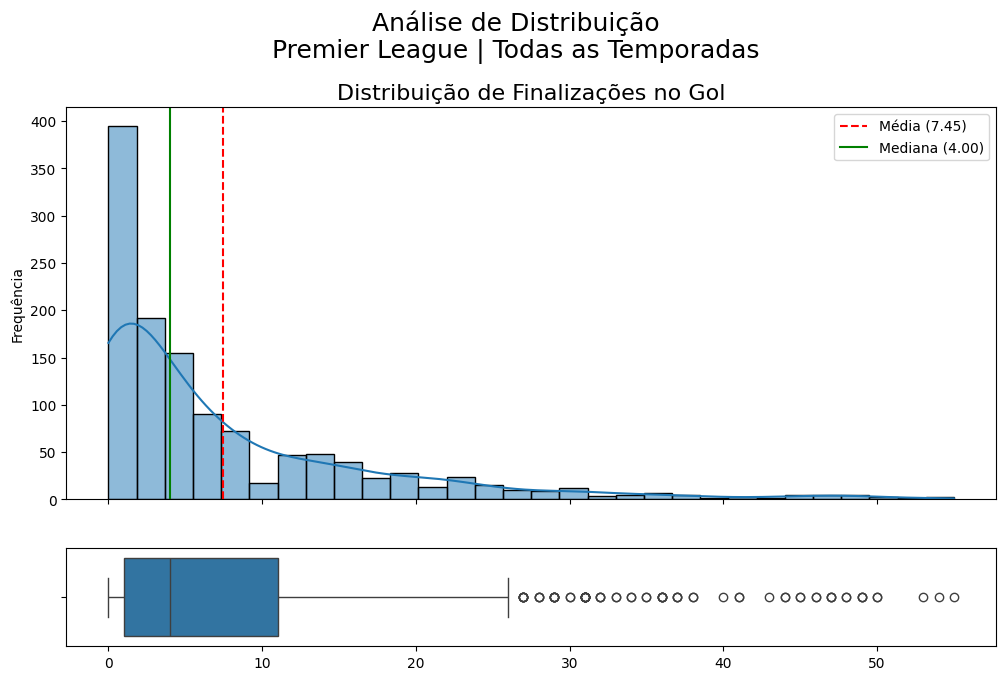

In [131]:
def resumo_metrica(df, metrica, temporadas=None, competicoes=None):
    # Filtra os dados
    df_filtrado = df.copy()
    titulo_temporada = "Todas as Temporadas"
    titulo_competicao = "Todas as Competições"
    if temporadas:
        df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
        titulo_temporada = ", ".join(map(str, temporadas))
    if competicoes:
        df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
        titulo_competicao = ", ".join(competicoes)

    if df_filtrado.empty or df_filtrado[metrica].isnull().all():
        print("Erro: Nenhum dado válido encontrado para os filtros selecionados.")
        return

    # 1. Cálculos Estatísticos
    dados_metrica = df_filtrado[metrica].dropna()
    media = dados_metrica.mean()
    mediana = dados_metrica.median()
    desvio_padrao = dados_metrica.std()
    q1 = dados_metrica.quantile(0.25)
    q3 = dados_metrica.quantile(0.75)

    print(f"--- Resumo Estatístico para '{metrica}' ---")
    print(f"Competições: {titulo_competicao} | Temporadas: {titulo_temporada}")
    print(f"Média: {media:.2f}")
    print(f"Mediana (Quartil 50%): {mediana:.2f}")
    print(f"Desvio Padrão: {desvio_padrao:.2f}")
    print(f"Quartil 25% (Q1): {q1:.2f}")
    print(f"Quartil 75% (Q3): {q3:.2f}")
    print(f"Mínimo: {dados_metrica.min():.2f}")
    print(f"Máximo: {dados_metrica.max():.2f}")

    # 2. Visualização Combinada
    fig, (ax_hist, ax_box) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.8, .2)}, figsize=(12, 7))
    
    # Histograma
    sns.histplot(dados_metrica, ax=ax_hist, kde=True)
    ax_hist.axvline(media, color='r', linestyle='--', label=f'Média ({media:.2f})')
    ax_hist.axvline(mediana, color='g', linestyle='-', label=f'Mediana ({mediana:.2f})')
    ax_hist.set_title(f'Distribuição de {metrica}', fontsize=16)
    ax_hist.set_ylabel('Frequência', fontsize=10)
    ax_hist.legend()
    
    # Boxplot
    sns.boxplot(x=dados_metrica, ax=ax_box)
    ax_box.set_xlabel('')

    plt.suptitle(f'Análise de Distribuição\n{titulo_competicao} | {titulo_temporada}', fontsize=18, y=1.02)
    plt.show()

# Exemplo de uso:
resumo_metrica(meu_dataframe, 'Finalizações no Gol', competicoes=['Premier League'])

Esta é uma versão aprimorada da primeira função. Em vez de apenas comparar o valor do jogador com a média, ela calcula o percentil do jogador. Isso oferece uma medida muito mais intuitiva de sua posição no ranking.

--- Análise de Posição para Mohamed Salah em 'Finalizações no Gol' ---
Valor do Jogador: 47.40
Percentil: O jogador está no percentil 99.48.
Isso significa que ele tem um valor maior que 99.48% dos jogadores no contexto selecionado.


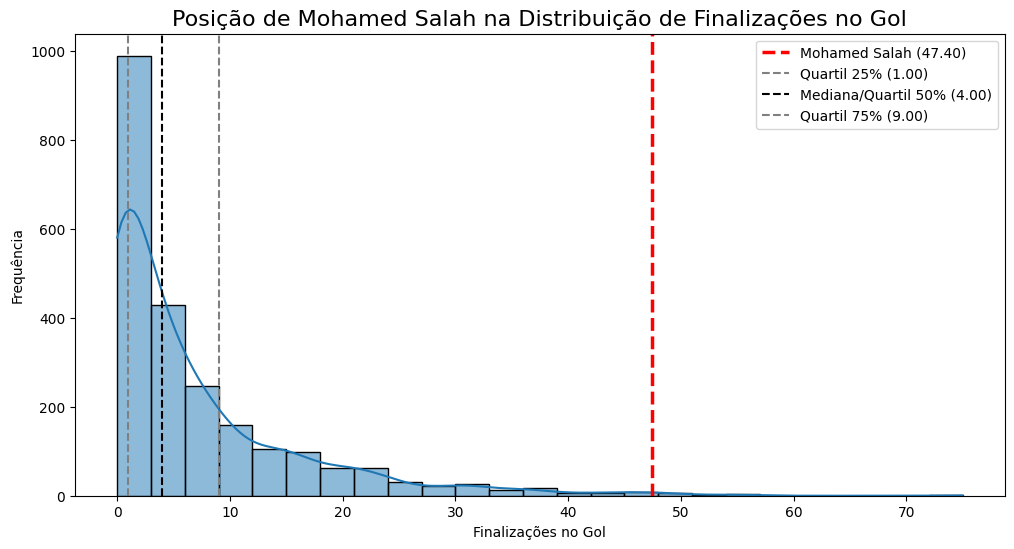

In [147]:
def resumo_metrica_com_jogador(df, nome_jogador, metrica, temporadas=None, competicoes=None):
    df_filtrado = df.copy()
    if temporadas: df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
    if competicoes: df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
    
    dados_jogador = df_filtrado[df_filtrado['Jogador'] == nome_jogador]
    if dados_jogador.empty:
        print(f"Erro: Jogador '{nome_jogador}' não encontrado para os filtros selecionados.")
        return

    dados_metrica = df_filtrado[metrica].dropna()
    valor_jogador = dados_jogador[metrica].mean()
    
    # 3. Cálculo do Percentil
    percentil_jogador = percentileofscore(dados_metrica, valor_jogador)
    
    q25, q50, q75 = dados_metrica.quantile(0.25), dados_metrica.quantile(0.5), dados_metrica.quantile(0.75)
    
    print(f"--- Análise de Posição para {nome_jogador} em '{metrica}' ---")
    print(f"Valor do Jogador: {valor_jogador:.2f}")
    print(f"Percentil: O jogador está no percentil {percentil_jogador:.2f}.")
    print(f"Isso significa que ele tem um valor maior que {percentil_jogador:.2f}% dos jogadores no contexto selecionado.")

    # 4. Visualização
    plt.figure(figsize=(12, 6))
    sns.histplot(dados_metrica, kde=True, bins=25)
    plt.axvline(valor_jogador, color='r', linestyle='--', linewidth=2.5, label=f'{nome_jogador} ({valor_jogador:.2f})')
    plt.axvline(q25, color='gray', linestyle='--', label=f'Quartil 25% ({q25:.2f})')
    plt.axvline(q50, color='black', linestyle='--', label=f'Mediana/Quartil 50% ({q50:.2f})')
    plt.axvline(q75, color='gray', linestyle='--', label=f'Quartil 75% ({q75:.2f})')
    
    plt.title(f'Posição de {nome_jogador} na Distribuição de {metrica}', fontsize=16)
    plt.xlabel(metrica)
    plt.ylabel('Frequência')
    plt.legend()
    plt.show()

# Exemplo de uso:
resumo_metrica_com_jogador(meu_dataframe, 'Mohamed Salah', 'Finalizações no Gol', competicoes=['Premier League', 'La Liga'])

Criar um gráfico de barras para comparar um valor agregado (soma total ou média) de uma métrica entre diferentes grupos (como Posições ou Times). É uma ferramenta visual clara para comparações diretas.

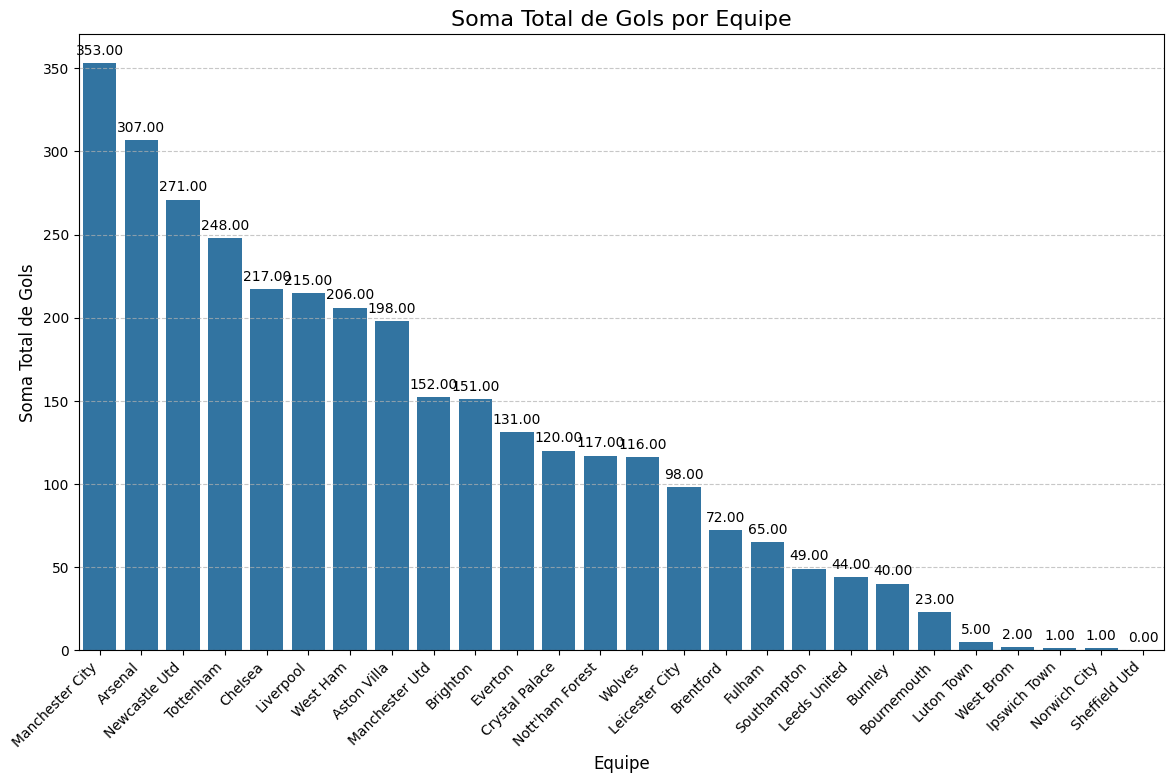

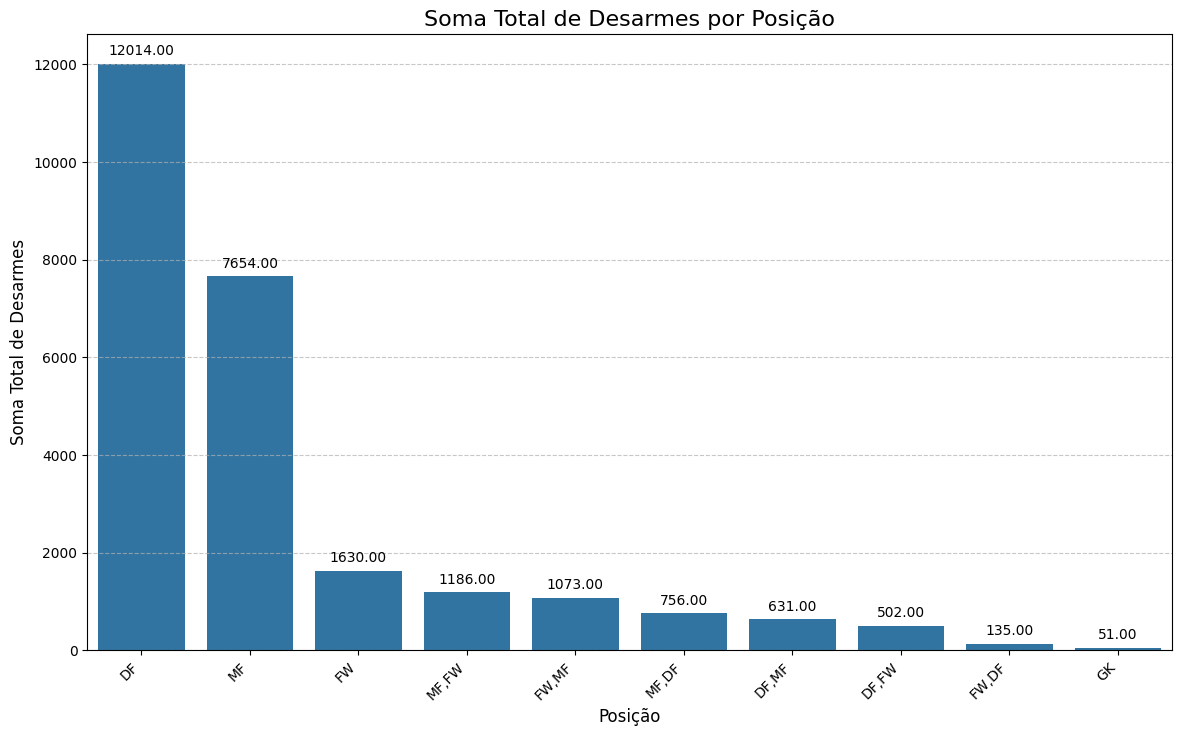

In [ ]:
def grafico_colunas(df, metrica, grupo_coluna, agregacao='mean', temporadas=None, competicoes=None):
    df_filtrado = df.copy()
    if temporadas: df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
    if competicoes: df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
    
    if df_filtrado.empty:
        print("Nenhum dado encontrado para os filtros.")
        return

    # 1. Agrega os dados pela média ou soma total
    if agregacao == 'media':
        dados_agregados = df_filtrado.groupby(grupo_coluna)[metrica].mean()
        titulo_agregacao = "Média"
    elif agregacao == 'total':
        dados_agregados = df_filtrado.groupby(grupo_coluna)[metrica].sum()
        titulo_agregacao = "Soma Total"
    else:
        print("Erro: O parâmetro 'agregacao' deve ser 'mean' ou 'sum'.")
        return

    # Ordena os dados para um gráfico mais limpo e prepara para o plot
    dados_agregados = dados_agregados.sort_values(ascending=False).reset_index()

    # 2. Cria o gráfico de barras
    plt.figure(figsize=(14, 8))
    ax = sns.barplot(x=grupo_coluna, y=metrica, data=dados_agregados)
    
    # 3. Adiciona os rótulos de dados em cima das colunas
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.2f'), 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha = 'center', va = 'center', 
                    xytext = (0, 9), 
                    textcoords = 'offset points')

    plt.title(f'{titulo_agregacao} de {metrica} por {grupo_coluna}', fontsize=16)
    plt.ylabel(f'{titulo_agregacao} de {metrica}', fontsize=12)
    plt.xlabel(grupo_coluna, fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()


grafico_colunas(
    meu_dataframe, 
    'Gols', 
    'Equipe', 
    agregacao='total',
    competicoes=['Premier League']
)
grafico_colunas(
    meu_dataframe, 
    'Desarmes', 
    'Posição', 
    agregacao='total',
    competicoes=['Serie A']
)

Analisar a performance de um jogador ao longo do tempo. Esta função é ideal para visualizar a trajetória de carreira de um jogador, identificando seu auge, declínio ou consistência.

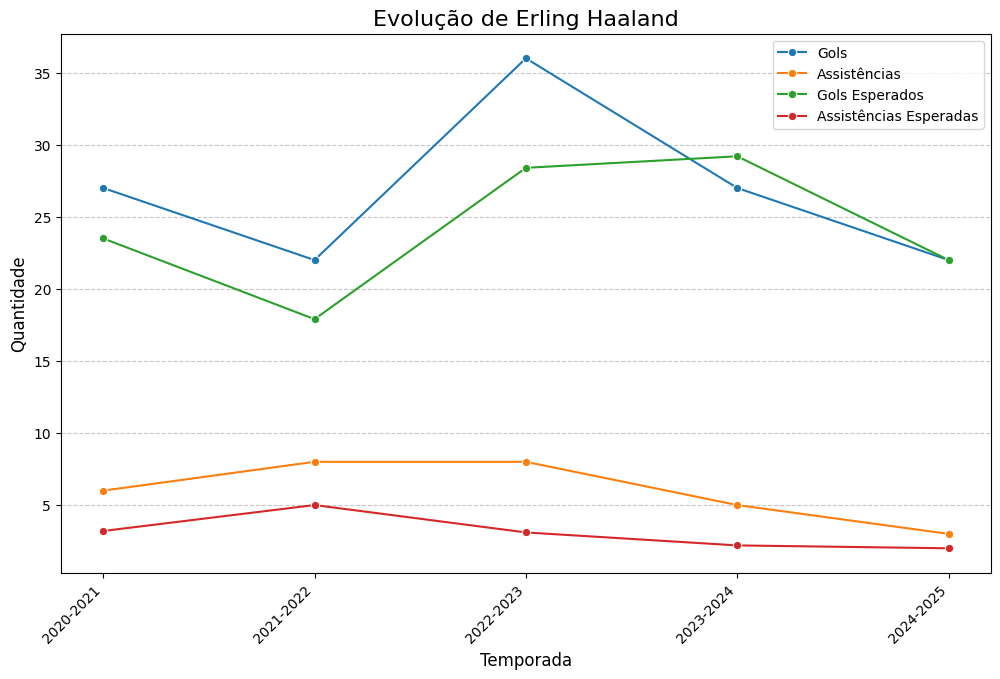

In [135]:
def evolucao_jogador(df, nome_jogador, metricas, competicoes=None):
    # Filtra os dados para o jogador e, opcionalmente, competições
    dados_jogador = df[df['Jogador'] == nome_jogador].copy()
    if competicoes:
        dados_jogador = dados_jogador[dados_jogador['Competição'].isin(competicoes)]

    if dados_jogador.empty:
        print(f"Nenhum dado encontrado para '{nome_jogador}' com os filtros aplicados.")
        return
    if len(dados_jogador['Temporada'].unique()) < 2:
        print(f"Dados de apenas uma temporada encontrados para '{nome_jogador}'. Não é possível plotar a evolução.")
        return

    # Garante que os dados estejam ordenados por temporada
    dados_jogador['Temporada'] = pd.Categorical(dados_jogador['Temporada'], ordered=True, categories=sorted(dados_jogador['Temporada'].unique()))
    dados_jogador.sort_values('Temporada', inplace=True)

    # Cria o gráfico
    plt.figure(figsize=(12, 7))
    for metrica in metricas:
        sns.lineplot(x='Temporada', y=metrica, data=dados_jogador, label=metrica, marker='o')

    plt.title(f'Evolução de {nome_jogador}', fontsize=16)
    plt.xlabel('Temporada', fontsize=12)
    plt.ylabel('Quantidade', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

# Exemplo de uso: Ver a evolução de Gols e Assistências de um jogador.
evolucao_jogador(
    meu_dataframe, 
    'Erling Haaland', 
    metricas=['Gols', 'Assistências', 'Gols Esperados', 'Assistências Esperadas'],
    competicoes=['Premier League', 'Bundesliga']
)

Semelhante à função anterior, mas focada em equipes. Ela permite analisar como o desempenho coletivo de um time mudou ao longo das temporadas, o que pode refletir mudanças táticas, de elenco ou de comando técnico.

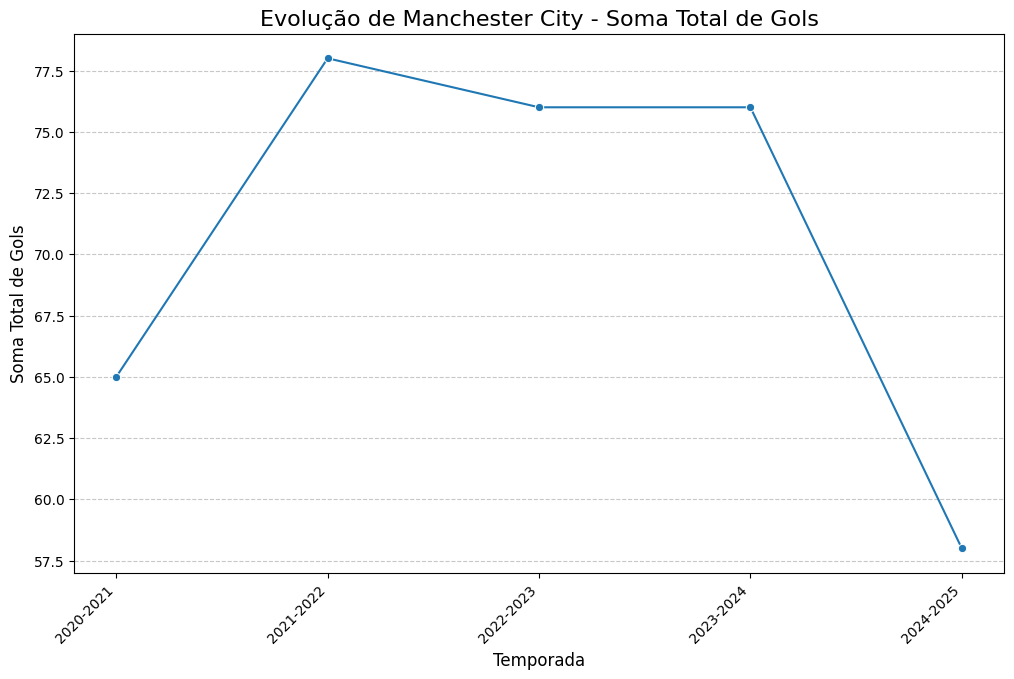

In [ ]:
def evolucao_equipe(df, nome_equipe, metrica, agregacao='sum', competicoes=None):
    dados_equipe = df[df['Equipe'] == nome_equipe].copy()
    if competicoes:
        dados_equipe = dados_equipe[dados_equipe['Competição'].isin(competicoes)]
    
    if dados_equipe.empty:
        print(f"Nenhum dado encontrado para '{nome_equipe}' com os filtros aplicados.")
        return
        
    # Agrupa por temporada e aplica a agregação
    if agregacao == 'total':
        evolucao = dados_equipe.groupby('Temporada')[metrica].sum().reset_index()
        titulo_agregacao = "Soma Total"
    elif agregacao == 'media':
        evolucao = dados_equipe.groupby('Temporada')[metrica].mean().reset_index()
        titulo_agregacao = "Média"
    else:
        print("Erro: 'agregacao' deve ser 'sum' ou 'mean'.")
        return
        
    evolucao.sort_values('Temporada', inplace=True)

    plt.figure(figsize=(12, 7))
    sns.lineplot(x='Temporada', y=metrica, data=evolucao, marker='o')
    plt.title(f'Evolução de {nome_equipe} - {titulo_agregacao} de {metrica}', fontsize=16)
    plt.xlabel('Temporada', fontsize=12)
    plt.ylabel(f'{titulo_agregacao} de {metrica}', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

# Exemplo de uso: Ver o total de Gols marcados pelo Manchester City a cada temporada.
evolucao_equipe(meu_dataframe, 'Manchester City', 'Gols', agregacao='total', competicoes=['Premier League'])

Investigar a relação entre a idade e o desempenho dos jogadores. O objetivo principal é identificar a "idade de auge", ou seja, a faixa etária em que os jogadores, em média, atingem seu pico de performance em uma determinada métrica.

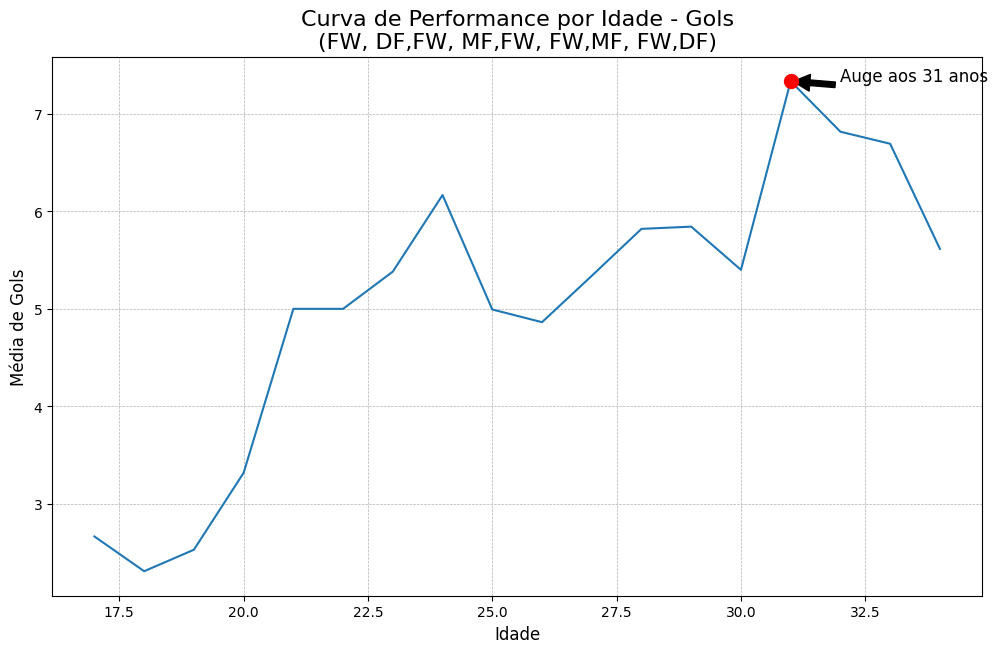

In [142]:
def analise_idade_performance(df, metrica, posicoes=None, competicoes=None, min_jogadores_por_idade=10):
    df_filtrado = df.copy()
    if competicoes:
        df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
    if posicoes:
        df_filtrado = df_filtrado[df_filtrado['Posição'].isin(posicoes)]

    # Agrupa por idade e calcula a média da métrica e a contagem de jogadores
    curva_idade = df_filtrado.groupby('Idade').agg(
        performance_media=(metrica, 'mean'),
        contagem_jogadores=('Jogador', 'nunique')
    ).reset_index()
    
    # Filtra idades com poucos jogadores
    curva_idade = curva_idade[curva_idade['contagem_jogadores'] >= min_jogadores_por_idade]
    
    if curva_idade.empty:
        print("Não há dados suficientes para gerar a curva de performance com os filtros atuais.")
        return

    # Encontra a idade do auge
    auge = curva_idade.loc[curva_idade['performance_media'].idxmax()]
    idade_auge = int(auge['Idade'])
    performance_auge = auge['performance_media']

    # Plota a curva
    plt.figure(figsize=(12, 7))
    sns.lineplot(x='Idade', y='performance_media', data=curva_idade)
    
    # Destaca o ponto do auge
    plt.scatter(idade_auge, performance_auge, color='red', s=100, zorder=5)
    plt.annotate(f'Auge aos {idade_auge} anos',
                 xy=(idade_auge, performance_auge),
                 xytext=(idade_auge + 1, performance_auge),
                 arrowprops=dict(facecolor='black', shrink=0.05),
                 fontsize=12)

    titulo_posicao = 'Todas as Posições' if not posicoes else ", ".join(posicoes)
    plt.title(f'Curva de Performance por Idade - {metrica}\n({titulo_posicao})', fontsize=16)
    plt.xlabel('Idade', fontsize=12)
    plt.ylabel(f'Média de {metrica}', fontsize=12)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.show()

posicoes_ataque = ['FW', 'DF,FW', 'MF,FW', 'FW,MF', 'FW,DF']
analise_idade_performance(
    meu_dataframe, 
    'Gols', 
    posicoes=posicoes_ataque, 
    min_jogadores_por_idade=10
)

Criar um ranking clássico dos "Top N" jogadores para uma métrica específica. É uma função essencial para qualquer ferramenta de análise, pois mostra de forma clara e direta quem são os destaques.

--- Top 10 Jogadores por 'Passes Chaves' ---


,Jogador,Passes Chaves,Minutos Jogados
135,Bruno Fernandes,91,3018
754,Raphinha,91,2839
644,Mohamed Salah,88,3371
166,Cole Palmer,87,3191
445,Joshua Kimmich,83,2847
756,Rayan Cherki,75,2041
727,Pedri,70,2879
537,Luis Milla,70,2875
160,Christian Pulisic,69,2478
890,Téji Savanier,67,2363


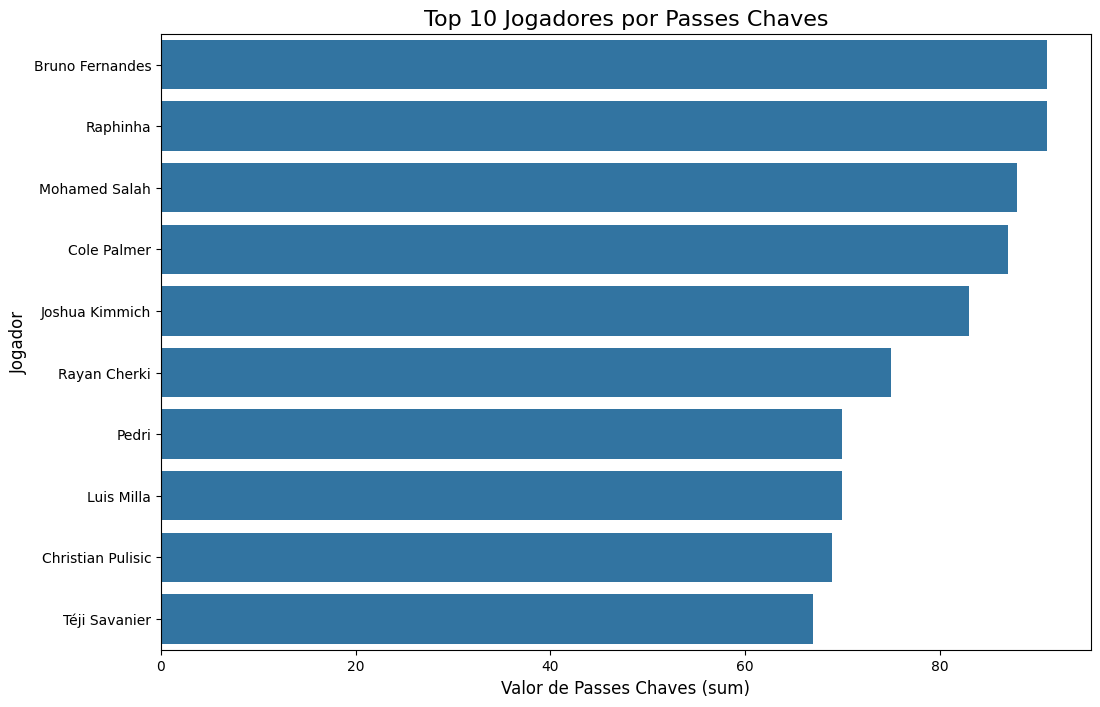

In [ ]:
def ranking_top_jogadores(df, metrica, agregacao='mean', n=10, min_minutos_jogados=900, temporadas=None, competicoes=None):
    df_filtrado = df.copy()
    if temporadas: df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
    if competicoes: df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
    
    # Agrupa por jogador para consolidar dados de múltiplas temporadas/competições
    agg_funcs = {metrica: agregacao, 'Minutos Jogados': 'sum'}
    jogadores_agregados = df_filtrado.groupby('Jogador').agg(agg_funcs).reset_index()

    # Filtra por minutos jogados
    jogadores_elegiveis = jogadores_agregados[jogadores_agregados['Minutos Jogados'] >= min_minutos_jogados]

    # Ordena e seleciona o top N
    top_jogadores = jogadores_elegiveis.sort_values(by=metrica, ascending=False).head(n)

    print(f"--- Top {n} Jogadores por '{metrica}' ---")
    display(top_jogadores[['Jogador', metrica, 'Minutos Jogados']])

    # Plota o gráfico
    plt.figure(figsize=(12, 8))
    sns.barplot(x=metrica, y='Jogador', data=top_jogadores, orient='h')
    plt.title(f'Top {n} Jogadores por {metrica}', fontsize=16)
    plt.xlabel(f'Valor de {metrica} ({agregacao})', fontsize=12)
    plt.ylabel('Jogador', fontsize=12)
    plt.show()

# Exemplo de uso: Top 10 criadores de chances (Passes Chave) nas 5 grandes ligas
ranking_top_jogadores(
    meu_dataframe, 
    metrica='Passes Chaves', 
    agregacao='sum', 
    n=10, 
    min_minutos_jogados=1500,
    temporadas=['2024-2025']
)

Uma análise mais avançada que busca identificar jogadores que não apenas têm um bom desempenho, mas o mantêm de forma estável ao longo de várias temporadas.

In [143]:
def ranking_jogadores_consistentes(df, metrica, n=10, min_temporadas=3, min_media_anual_minutos=900):
    # Agrupa por jogador e temporada
    dados_sazonais = df.groupby(['Jogador', 'Temporada']).agg(
        valor_metrica=(metrica, 'mean'),
        minutos=( 'Minutos Jogados', 'sum')
    ).reset_index()

    # Filtra jogadores que não atingem a média de minutos
    dados_sazonais = dados_sazonais[dados_sazonais['minutos'] >= min_media_anual_minutos]

    # Calcula as estatísticas de consistência
    consistencia = dados_sazonais.groupby('Jogador').agg(
        media_performance=( 'valor_metrica', 'mean'),
        desvio_padrao=('valor_metrica', 'std'),
        num_temporadas=('Temporada', 'nunique')
    ).reset_index()

    # Filtra por número mínimo de temporadas
    consistencia = consistencia[consistencia['num_temporadas'] >= min_temporadas]

    # Calcula o Coeficiente de Variação (CV). Preenche NaNs (desvio padrão 0) com 0.
    consistencia['CV'] = (consistencia['desvio_padrao'] / consistencia['media_performance']).fillna(0)

    # Rankeia por CV (menor é mais consistente), para jogadores com alta performance (acima da mediana)
    mediana_performance = consistencia['media_performance'].median()
    consistencia = consistencia[consistencia['media_performance'] >= mediana_performance]
    
    top_consistentes = consistencia.sort_values(by='CV', ascending=True).head(n)

    print(f"--- Top {n} Jogadores Mais Consistentes em '{metrica}' (Performance Acima da Mediana) ---")
    display(top_consistentes[['Jogador', 'media_performance', 'CV', 'num_temporadas']])
    return

# Exemplo de uso:
ranking_jogadores_consistentes(meu_dataframe, metrica='Passes Chaves', min_temporadas=4)

--- Top 10 Jogadores Mais Consistentes em 'Passes Chaves' (Performance Acima da Mediana) ---


,Jogador,media_performance,CV,num_temporadas
386,Jeffrey Schlupp,18.25,0.027397,4
869,Vincenzo Grifo,61.60,0.090822,5
252,Erling Haaland,27.40,0.095171,5
583,Matteo Pessina,25.00,0.097980,4
426,Joshua Kimmich,77.00,0.100597,5
153,Christian Eriksen,30.80,0.106204,5
602,Maximilian Arnold,48.40,0.110879,5
831,Theo Hernández,44.20,0.119074,5
291,Gabriel Jesus,32.00,0.127578,4
221,Eberechi Eze,53.00,0.129810,4


Identificar os jogadores que tiveram o maior salto de performance entre duas temporadas consecutivas. É excelente para encontrar "jogadores revelação" ou aqueles que tiveram uma temporada de destaque.

In [ ]:
def ranking_jogadores_revelacao(df, metrica, temporada_anterior, temporada_atual, n=10, min_minutos_em_ambas=500):
    # Filtra dados para cada temporada
    df_ant = df[(df['Temporada'] == temporada_anterior) & (df['Minutos Jogados'] >= min_minutos_em_ambas)]
    df_atu = df[(df['Temporada'] == temporada_atual) & (df['Minutos Jogados'] >= min_minutos_em_ambas)]

    # Junta os dataframes
    df_comp = pd.merge(df_ant, df_atu, on='Jogador', suffixes=(f'_{temporada_anterior}', f'_{temporada_atual}'))
    
    # Calcula a melhora
    df_comp['Melhora'] = df_comp[f'{metrica}_{temporada_atual}'] - df_comp[f'{metrica}_{temporada_anterior}']
    
    # Ordena pela melhora
    top_revelacoes = df_comp.sort_values(by='Melhora', ascending=False).head(n)

    print(f"--- Top {n} Jogadores com Maior Crescimento em '{metrica}' ---")
    print(f"Comparando {temporada_anterior} com {temporada_atual}")
    display(top_revelacoes[['Jogador', f'{metrica}_{temporada_anterior}', f'{metrica}_{temporada_atual}', 'Melhora']])
    return

# Exemplo de uso:
ranking_jogadores_revelacao(
    meu_dataframe, 
    'Gols', 
    '2023-2024', 
    '2024-2025'
)

--- Top 10 Jogadores com Maior Crescimento em 'Gols' ---
Comparando 2023-2024 com 2024-2025


,Jogador,Gols_2023-2024,Gols_2024-2025,Melhora
496,Moise Kean,0,19,19
548,Ousmane Dembélé,3,21,18
558,Patrik Schick,7,21,14
584,Raphinha,6,18,12
493,Mohamed Salah,18,29,11
406,Ludovic Ajorque,2,13,11
258,Hugo Ekitike,4,15,11
536,Oihan Sancet,4,15,11
318,Jonathan Burkardt,8,18,10
81,Ayoze Pérez,9,19,10


Esta é uma poderosa função de benchmarking que vai além de comparar com médias. Ela encontra os jogadores individuais cujos perfis estatísticos são mais parecidos com um jogador de referência, usando um conjunto de métricas.

In [ ]:
def encontrar_jogadores_similares(df, nome_jogador, metricas_comparacao, n=5, temporadas=None, competicoes=None):
    df_filtrado = df.copy()
    if temporadas: df_filtrado = df_filtrado[df_filtrado['Temporada'].isin(temporadas)]
    if competicoes: df_filtrado = df_filtrado[df_filtrado['Competição'].isin(competicoes)]
    
    # Preparação dos dados
    df_metricas = df_filtrado.set_index('Jogador')[metricas_comparacao].dropna()
    
    # Normalização (essencial para a distância euclidiana)
    scaler = StandardScaler()
    df_scaled = pd.DataFrame(scaler.fit_transform(df_metricas), index=df_metricas.index, columns=df_metricas.columns)

    if nome_jogador not in df_scaled.index:
        print(f"Erro: '{nome_jogador}' não encontrado nos dados filtrados para comparação.")
        return

    # Encontra o jogador de referência
    vetor_jogador = df_scaled.loc[[nome_jogador]]

    # Calcula a distância de todos para o jogador de referência
    distancias = cdist(vetor_jogador, df_scaled, metric='euclidean').flatten()
    
    # Cria um DataFrame de similaridade
    df_similaridade = pd.DataFrame({'similaridade': distancias}, index=df_scaled.index).sort_values('similaridade')
    
    # Exibe os N mais próximos (excluindo o próprio jogador, que terá distância 0)
    top_similares = df_similaridade.iloc[1:n+1]
    
    print(f"--- Top {n} Jogadores Mais Similares a {nome_jogador} ---")
    print(top_similares)
    
    # Mostra as estatísticas dos jogadores similares para comparação
    print("\n--- Estatísticas dos Jogadores Similares (valores originais) ---")
    display(df_metricas.loc[top_similares.index])
    return

# Exemplo de uso: Encontrar meias similares a 'Kevin De Bruyne'
metricas_meia_criador = [
    'Assistências / 90', 'Gols Assistidos Esperados / 90', 'Passes Chaves', 
    'Passes Completos no Terço Final do Campo', 'Passes Progressivos Efetuados'
]
encontrar_jogadores_similares(
    meu_dataframe, 
    'Kevin De Bruyne', 
    metricas_meia_criador, 
    temporadas=['2024-2025']
)

--- Top 5 Jogadores Mais Similares a Kevin De Bruyne ---
                 similaridade
Jogador                      
Ousmane Dembélé      0.698721
Julian Brandt        0.974171
Lee Kang-in          1.331480
Son Heung-min        1.456782
Jonathan Clauss      1.622912

--- Estatísticas dos Jogadores Similares (valores originais) ---


,Assistências / 90,Gols Assistidos Esperados / 90,Passes Chaves,Passes Completos no Terço Final do Campo,Passes Progressivos Efetuados
Jogador,,,,,
Ousmane Dembélé,0.31,0.43,63,93,137
Julian Brandt,0.39,0.33,61,94,149
Lee Kang-in,0.32,0.30,56,103,143
Son Heung-min,0.38,0.35,50,40,111
Jonathan Clauss,0.31,0.30,55,70,105
